# Hình trực quan hóa
Chạy các mục lần lượt. Mỗi cell hiển thị biểu đồ và lưu ảnh vào thư mục output của bài tương ứng.


## Câu 1 — Quỹ đạo cuối của ba hạt sau 30 giây

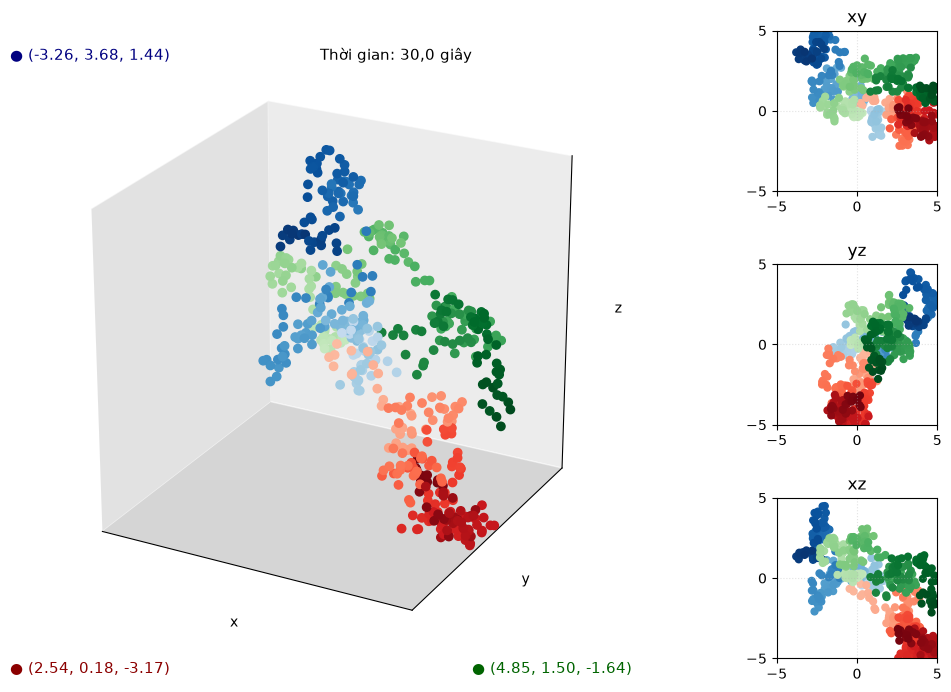

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SO_HAT, SO_KHUNG, FPS, GIOI_HAN = 3, 180, 6, 5
rng = np.random.default_rng(12)
buoc = rng.normal(0, 0.30, (SO_KHUNG - 1, SO_HAT, 3))
vi_tri = np.zeros((SO_KHUNG, SO_HAT, 3))
for i in range(1, SO_KHUNG):
    vi_tri[i] = vi_tri[i - 1] + buoc[i - 1]
    vi_tri[i] = np.where(vi_tri[i] > GIOI_HAN, 2 * GIOI_HAN - vi_tri[i], vi_tri[i])
    vi_tri[i] = np.where(vi_tri[i] < -GIOI_HAN, -2 * GIOI_HAN - vi_tri[i], vi_tri[i])

fig = plt.figure(figsize=(11, 7.3), facecolor='white')
ax = fig.add_axes([0.04, 0.11, 0.66, 0.80], projection='3d')
ax.set(xlim=(-5,5), ylim=(-5,5), zlim=(-5,5), xlabel='x', ylabel='y', zlabel='z')
ax.set_box_aspect((1,1,1)); ax.view_init(elev=24, azim=-62); ax.grid(False)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
for pane, shade in zip((ax.xaxis.pane,ax.yaxis.pane,ax.zaxis.pane),(0.78,0.86,0.68)):
    pane.set_facecolor((shade,shade,shade,1)); pane.set_edgecolor('white')
projections=[]
for j,name in enumerate(('xy','yz','xz')):
    a=fig.add_axes([0.76,0.73-j*0.32,0.18,0.22])
    a.set(xlim=(-5,5),ylim=(-5,5),title=name); a.set_aspect('equal')
    a.set_xticks([-5,0,5]); a.set_yticks([-5,0,5]); a.grid(alpha=.35,linestyle=':')
    projections.append(a)
colors=['Blues','Reds','Greens']; labels=['navy','darkred','darkgreen']
for k in range(SO_HAT):
    path=vi_tri[:,k,:]
    shades=plt.get_cmap(colors[k])(np.linspace(.25,.98,len(path)))
    ax.scatter(path[:,0],path[:,1],path[:,2],s=36,color=shades,depthshade=False)
    for a,pair in zip(projections,((0,1),(1,2),(0,2))):
        a.scatter(path[:,pair[0]],path[:,pair[1]],s=24,color=shades)
    x,y,z=path[-1]
    fig.text([.08,.08,.50][k],[.91,.07,.07][k],f'● ({x:.2f}, {y:.2f}, {z:.2f})',color=labels[k],fontsize=11)
fig.text(.50,.91,'Thời gian: 30,0 giây',ha='right',fontsize=11)
fig.savefig('Cau_1_Brown/output/anh_brown.png',dpi=120)
plt.show()


## Câu 2 — Nến thống kê và màu theo giá đóng cửa

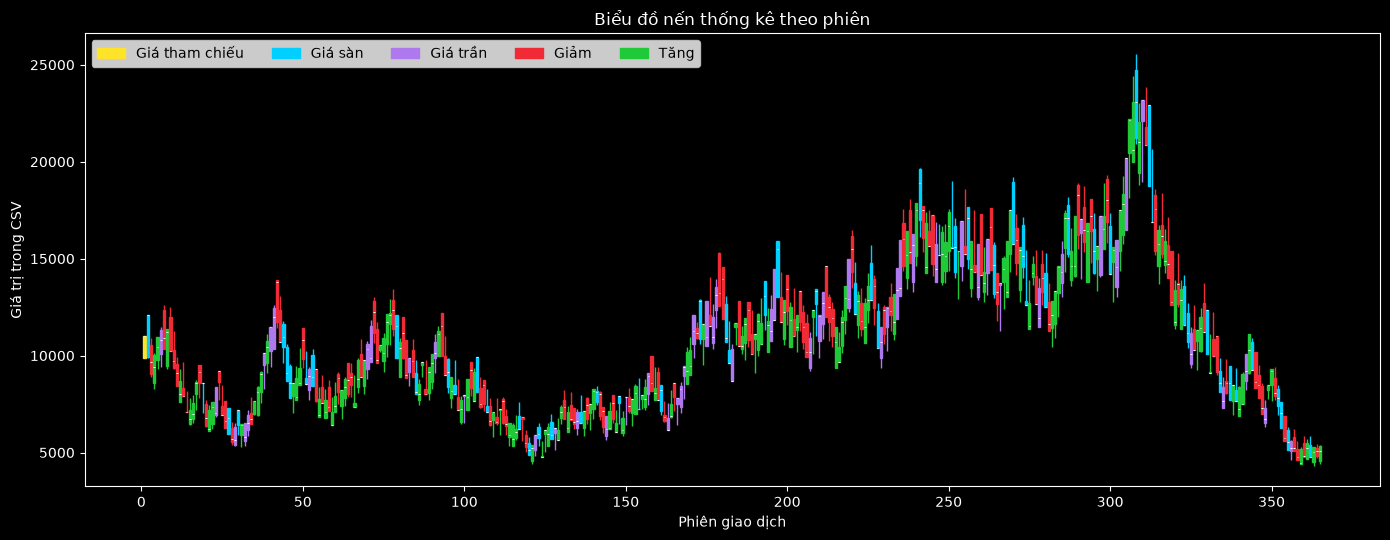

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

raw = np.loadtxt('Cau_2_Co_Phieu/data/abc-2.csv', delimiter=',')
reference = np.empty(len(raw)); values = np.empty_like(raw)
reference[0] = raw[0,6]
for i in range(len(raw)):
    if i: reference[i] = values[i-1,6]
    values[i] = np.clip(raw[i], reference[i]*.9, reference[i]*1.1)
close = values[:,6]; floor=reference*.9; ceiling=reference*1.1
low=values.min(axis=1); high=values.max(axis=1)
q1,median,q3=np.percentile(values,[25,50,75],axis=1)
colors={'floor':'#00cfff','ceiling':'#ae78ef','reference':'#ffe329',
        'down':'#f12b36','up':'#20c938'}

def candle_color(i):
    if abs(close[i]-floor[i]) < 1e-8: return colors['floor']
    if abs(close[i]-ceiling[i]) < 1e-8: return colors['ceiling']
    if abs(close[i]-reference[i]) < 1e-8: return colors['reference']
    return colors['down'] if close[i] < reference[i] else colors['up']

fig,ax=plt.subplots(figsize=(14,5.5)); fig.patch.set_facecolor('black'); ax.set_facecolor('black')
for i in range(len(values)):
    x=i+1; color=candle_color(i)
    ax.vlines(x,low[i],high[i],color=color,lw=1)
    ax.add_patch(Rectangle((x-.34,q1[i]),.68,max(q3[i]-q1[i],.01),color=color))
    ax.hlines(median[i],x-.25,x+.25,color='white',lw=.7)
ax.set(title='Biểu đồ nến thống kê theo phiên',xlabel='Phiên giao dịch',ylabel='Giá trị trong CSV')
ax.tick_params(colors='white'); ax.title.set_color('white'); ax.xaxis.label.set_color('white'); ax.yaxis.label.set_color('white')
for spine in ax.spines.values(): spine.set_color('white')
ax.legend(handles=[Patch(color=colors['reference'],label='Giá tham chiếu'),
                   Patch(color=colors['floor'],label='Giá sàn'),Patch(color=colors['ceiling'],label='Giá trần'),
                   Patch(color=colors['down'],label='Giảm'),Patch(color=colors['up'],label='Tăng')],ncol=5,loc='upper left')
fig.tight_layout(); fig.savefig('Cau_2_Co_Phieu/output/co_phieu.png',dpi=160,facecolor='black')
plt.show()


## Câu 3 — Tương quan và ba mô hình hồi quy

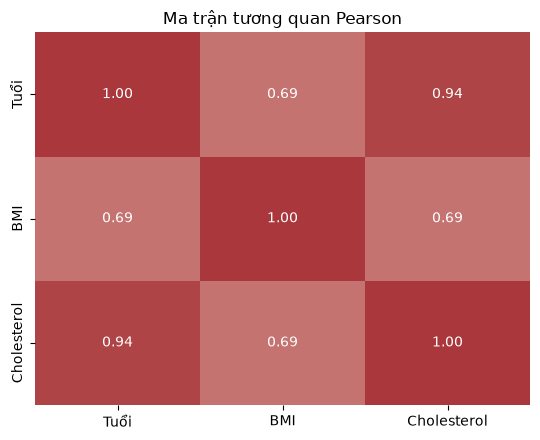

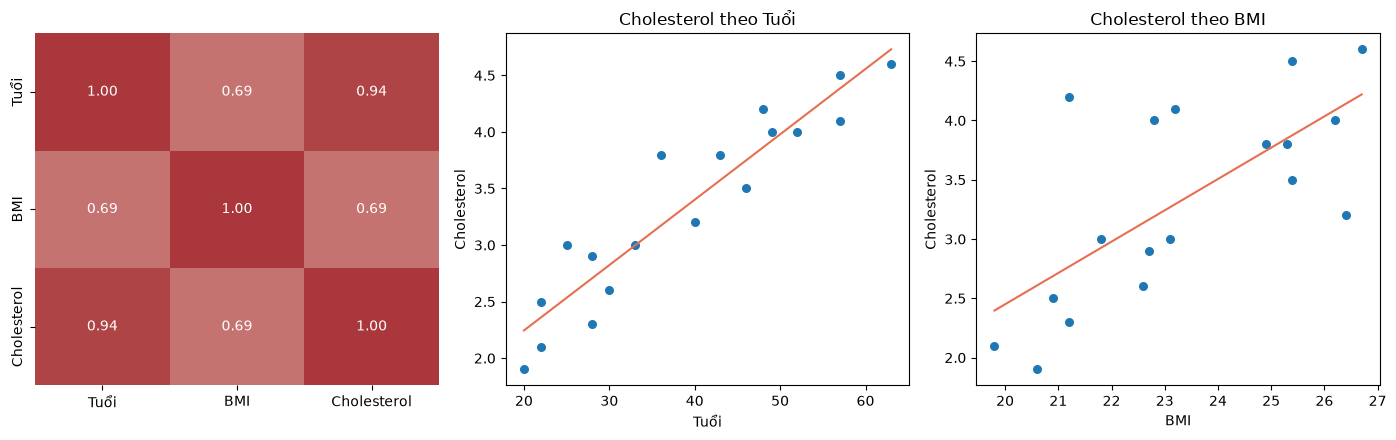

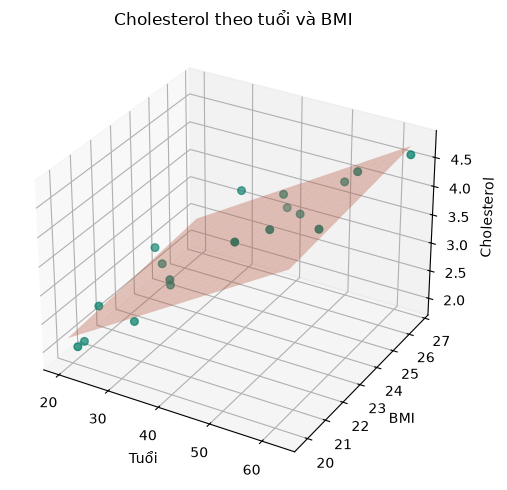

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

data=np.genfromtxt('Cau_3_Hoi_Quy/data/health.csv',delimiter=',',skip_header=1)
age,bmi,chol=data.T
models=[LinearRegression().fit(age[:,None],chol),
        LinearRegression().fit(bmi[:,None],chol),
        LinearRegression().fit(data[:,:2],chol)]
fig_corr,ax_corr=plt.subplots(figsize=(5.5,4.5))
sns.heatmap(np.corrcoef(data.T),annot=True,fmt='.2f',cmap='vlag',center=0,
            xticklabels=['Tuổi','BMI','Cholesterol'],yticklabels=['Tuổi','BMI','Cholesterol'],ax=ax_corr,cbar=False)
ax_corr.set_title('Ma trận tương quan Pearson')
fig_corr.tight_layout(); fig_corr.savefig('Cau_3_Hoi_Quy/output/tuong_quan.png',dpi=160)
plt.show()

fig,axes=plt.subplots(1,3,figsize=(14,4.5))
sns.heatmap(np.corrcoef(data.T),annot=True,fmt='.2f',cmap='vlag',center=0,
            xticklabels=['Tuổi','BMI','Cholesterol'],yticklabels=['Tuổi','BMI','Cholesterol'],ax=axes[0],cbar=False)
for ax,x,model,label in [(axes[1],age,models[0],'Tuổi'),(axes[2],bmi,models[1],'BMI')]:
    ax.scatter(x,chol,s=30); grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,model.predict(grid[:,None]),color='#e76f51')
    ax.set(title=f'Cholesterol theo {label}',xlabel=label,ylabel='Cholesterol')
fig.tight_layout(); fig.savefig('Cau_3_Hoi_Quy/output/hoi_quy_don.png',dpi=160)
plt.show()

fig=plt.figure(figsize=(7,5)); ax=fig.add_subplot(111,projection='3d')
ag_grid,bmi_grid=np.meshgrid(np.linspace(age.min(),age.max(),20),np.linspace(bmi.min(),bmi.max(),20))
plane=models[2].predict(np.c_[ag_grid.ravel(),bmi_grid.ravel()]).reshape(ag_grid.shape)
ax.plot_surface(ag_grid,bmi_grid,plane,color='#e76f51',alpha=.35,edgecolor='none')
ax.scatter(age,bmi,chol,color='#087f6b',s=30)
ax.set(title='Cholesterol theo tuổi và BMI',xlabel='Tuổi',ylabel='BMI',zlabel='Cholesterol')
fig.tight_layout(); fig.savefig('Cau_3_Hoi_Quy/output/hoi_quy_hai_bien.png',dpi=160)
plt.show()


## Câu 4 — GDP, lạm phát và mối liên hệ

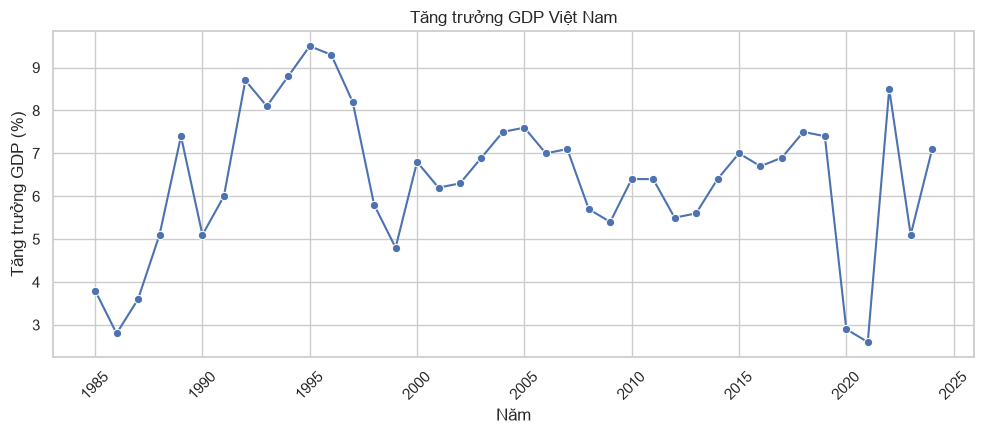

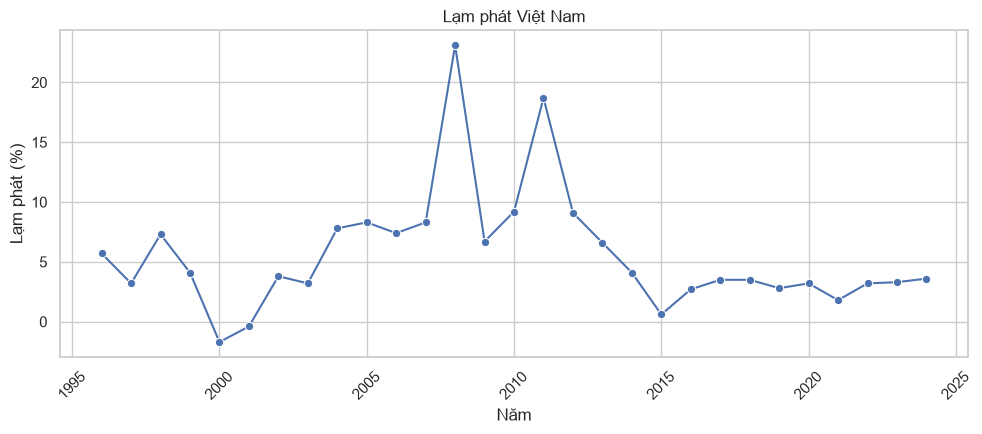

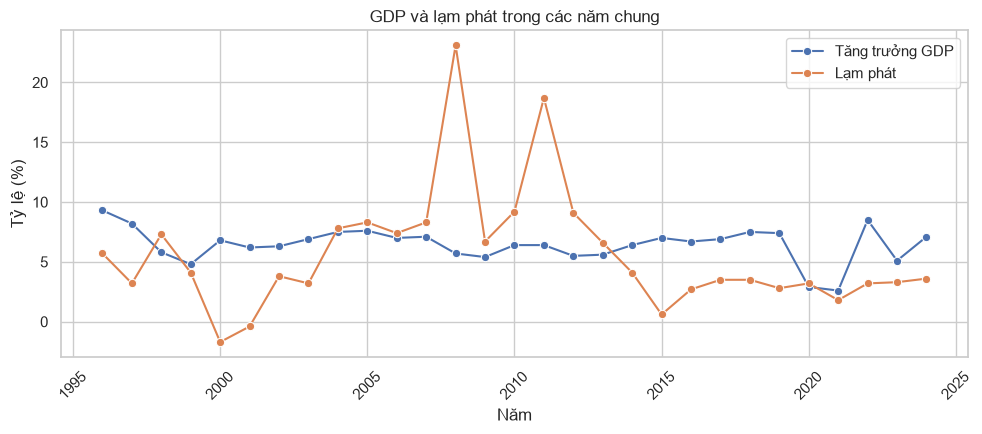

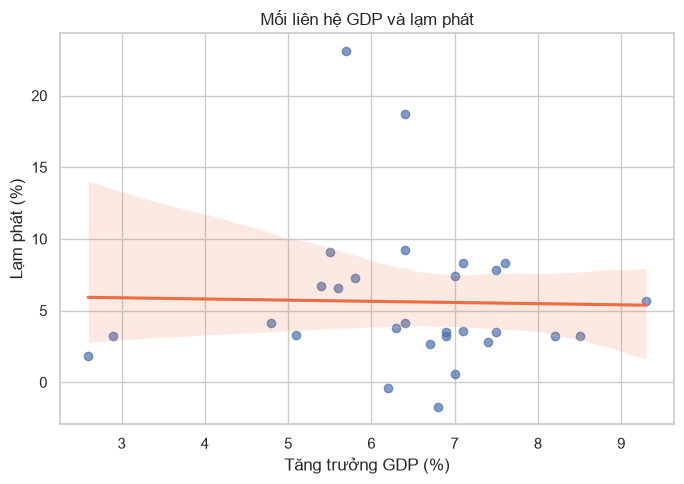

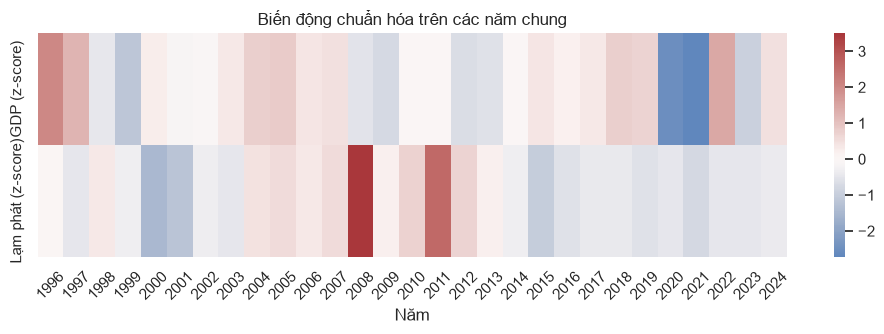

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

gdp=np.genfromtxt('Cau_4_GDP_Lam_Phat/data/vietnam_gdp_growth_1985_2024.csv',delimiter=',',skip_header=1)
infl=np.genfromtxt('Cau_4_GDP_Lam_Phat/data/vietnam_inflation_1996_2024.csv',delimiter=',',skip_header=1)
sns.set_theme(style='whitegrid')

def draw_line(data,title,ylabel,filename):
    fig,ax=plt.subplots(figsize=(10,4.5))
    sns.lineplot(x=data[:,0],y=data[:,1],marker='o',ax=ax)
    ax.set(title=title,xlabel='Năm',ylabel=ylabel); ax.tick_params(axis='x',rotation=45)
    fig.tight_layout(); fig.savefig(filename,dpi=160); plt.show()
draw_line(gdp,'Tăng trưởng GDP Việt Nam','Tăng trưởng GDP (%)','Cau_4_GDP_Lam_Phat/output/gdp_1985_2024.png')
draw_line(infl,'Lạm phát Việt Nam','Lạm phát (%)','Cau_4_GDP_Lam_Phat/output/lam_phat_1996_2024.png')

years=np.intersect1d(gdp[:,0],infl[:,0])
g=np.array([gdp[gdp[:,0]==y,1][0] for y in years]); p=np.array([infl[infl[:,0]==y,1][0] for y in years])
fig,ax=plt.subplots(figsize=(10,4.5))
sns.lineplot(x=years,y=g,marker='o',label='Tăng trưởng GDP',ax=ax)
sns.lineplot(x=years,y=p,marker='o',label='Lạm phát',ax=ax)
ax.set(title='GDP và lạm phát trong các năm chung',xlabel='Năm',ylabel='Tỷ lệ (%)'); ax.tick_params(axis='x',rotation=45)
fig.tight_layout(); fig.savefig('Cau_4_GDP_Lam_Phat/output/gdp_lam_phat_theo_nam.png',dpi=160); plt.show()
fig,ax=plt.subplots(figsize=(7,5)); sns.regplot(x=g,y=p,ax=ax,scatter_kws={'alpha':.7},line_kws={'color':'#ef6c42'})
ax.set(title='Mối liên hệ GDP và lạm phát',xlabel='Tăng trưởng GDP (%)',ylabel='Lạm phát (%)')
fig.tight_layout(); fig.savefig('Cau_4_GDP_Lam_Phat/output/quan_he_gdp_lam_phat.png',dpi=160); plt.show()
z=np.c_[(g-g.mean())/g.std(),(p-p.mean())/p.std()]
fig,ax=plt.subplots(figsize=(10,3.5))
sns.heatmap(z.T,center=0,cmap='vlag',xticklabels=years.astype(int),yticklabels=['GDP (z-score)','Lạm phát (z-score)'],ax=ax)
ax.set(title='Biến động chuẩn hóa trên các năm chung',xlabel='Năm'); ax.tick_params(axis='x',rotation=45)
fig.tight_layout(); fig.savefig('Cau_4_GDP_Lam_Phat/output/heatmap_chuan_hoa.png',dpi=160); plt.show()
